In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

data = get_runs_data(
    tag="2a-functions",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
    ],
)
show_config_differences(data)

Found 33 runs with tag '2a-functions'


,cfg.dataset.npz_path,cfg.training.max_steps,cfg.dataset_metadata.seed,cfg.dataset_metadata.strategy,cfg.dataset_metadata.aggregation,cfg.dataset_metadata.target_level
_run_id,,,,,,
2rszl2ex,datasets/level_2a_strategy_random_seed_4.npz,8000,4,random,lookup,2a
4z8wd3uv,datasets/level_2a_strategy_lookback_aggregatio...,8000,15,lookback,formula,2a
5nmaxwb3,datasets/level_2a_strategy_polynomial_prime_ag...,8000,15,polynomial_prime,formula,2a
64cudkub,datasets/level_2a_strategy_sin_seed_3.npz,8000,3,sin,lookup,2a
6y7gc7vw,datasets/level_2a_strategy_sin_aggregation_loo...,8000,0,sin,lookup,2a
7f948578,datasets/level_2a_strategy_polynomial_prime_ag...,8000,42,polynomial_prime,formula,2a
7u0uukcz,datasets/level_2a_strategy_modulo_modulus_8_se...,8000,3,modulo,lookup,2a
92k5x25y,datasets/level_1_strategy_formula_pos_0...,5500,0,formula,None,1
dc78hemf,datasets/level_2a_strategy_lookback_aggregatio...,8000,0,lookback,lookup,2a


In [17]:
LEVEL_COL = "cfg.dataset_metadata.target_level"
STRATEGY_COL = "cfg.dataset_metadata.strategy"
AGGREGATION_COL = "cfg.dataset_metadata.aggregation"
METRIC_NAME = "train/exact_match_repeated"
SEED_COL = "cfg.dataset_metadata.seed"
STEP_COL = "train/global_step"

def plot_all_runs(aggregation_method, max_step=5500):
    filtered_data = data[
        ((data[STRATEGY_COL] == aggregation_method) | (data[AGGREGATION_COL] == aggregation_method))
    ]
    filtered_data = filtered_data[filtered_data[STEP_COL] <= max_step]

    # Aggregate by level, strategy, aggregation, and step (across seeds)
    groups = filtered_data.groupby(
        [LEVEL_COL, STRATEGY_COL, AGGREGATION_COL, STEP_COL], dropna=False
    )[METRIC_NAME].agg(['mean', 'std']).reset_index()

    # Plot each (level, strategy, aggregation) combination
    plt.figure(figsize=(10, 6))
    for (level, strategy, aggregation), g in groups.groupby([LEVEL_COL, STRATEGY_COL, AGGREGATION_COL], dropna=False):
        label = f"Level {level}"
        if level == "2a":
            label += f" - {strategy}"

        steps = g[STEP_COL]
        mean = g['mean']
        std = g['std'].fillna(0)  # Handle single-seed cases

        plt.plot(steps, mean, label=label)
        plt.fill_between(steps, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2)

    plt.xlabel("Steps", fontsize=20)
    plt.ylabel("Exact Match", fontsize=20)
    plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.45), ncol=3, fontsize=18)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    # plt.title(f"{aggregation_method.capitalize()} Method", fontsize=18)
    plt.savefig(f"plots/{aggregation_method}-all-methods.pdf", bbox_inches='tight')

def plot_aggregated_by_level(aggregation_method, max_step=5500):
    filtered_data = data[
        ((data[STRATEGY_COL] == aggregation_method) | (data[AGGREGATION_COL] == aggregation_method))
    ]
    filtered_data = filtered_data[filtered_data[STEP_COL] <= max_step]
    level_groups = filtered_data.groupby([LEVEL_COL, STEP_COL])[METRIC_NAME].agg(['mean', 'std']).reset_index()
    
    plt.figure(figsize=(10, 6))
    for level in sorted(level_groups[LEVEL_COL].unique(), key=str):
        level_data = level_groups[level_groups[LEVEL_COL] == level]
        steps = level_data[STEP_COL]
        mean = level_data['mean']
        std = level_data['std']

        plt.plot(steps, mean, label=f"Level {level}")
        plt.fill_between(steps, (mean - std).clip(0, 1), (mean + std).clip(0, 1), alpha=0.2)

    plt.xlabel("Steps", fontsize=20)
    plt.ylabel("Exact Match", fontsize=20)
    plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=18)
    plt.tick_params(axis='both', labelsize=18)
    # plt.title(f"{aggregation_method.capitalize()} Method per Level", fontsize=18)
    plt.tight_layout()
    plt.savefig(f"plots/{aggregation_method}-per-level.pdf")

In [3]:
# plot_all_runs("formula")

In [4]:
# plot_aggregated_by_level("formula")

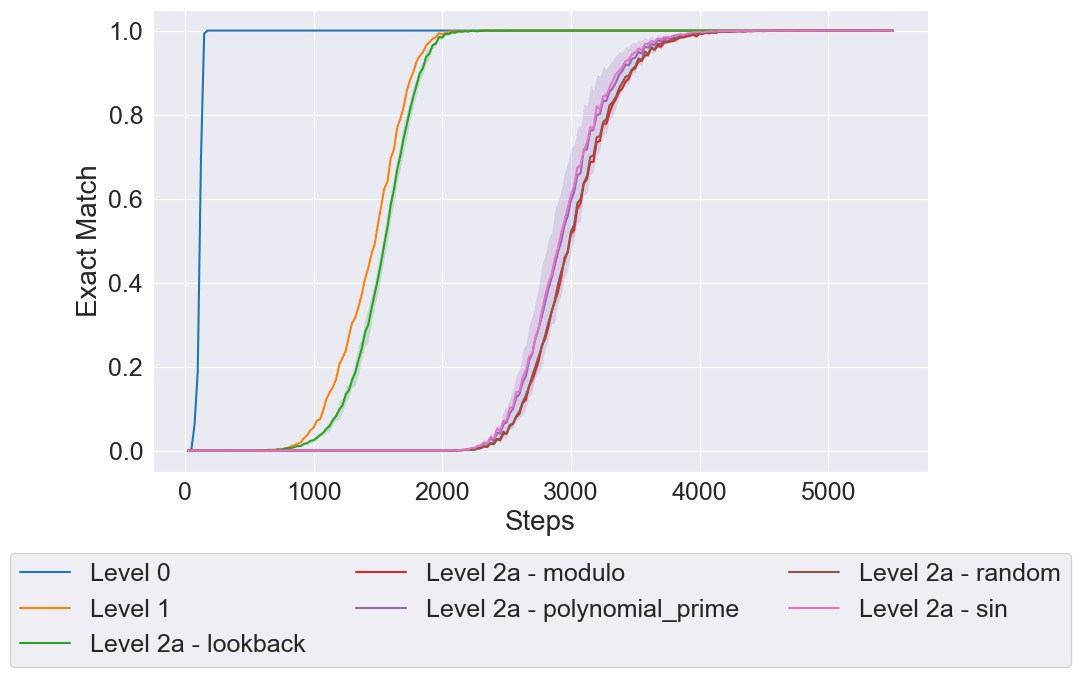

In [14]:
plot_all_runs("lookup")

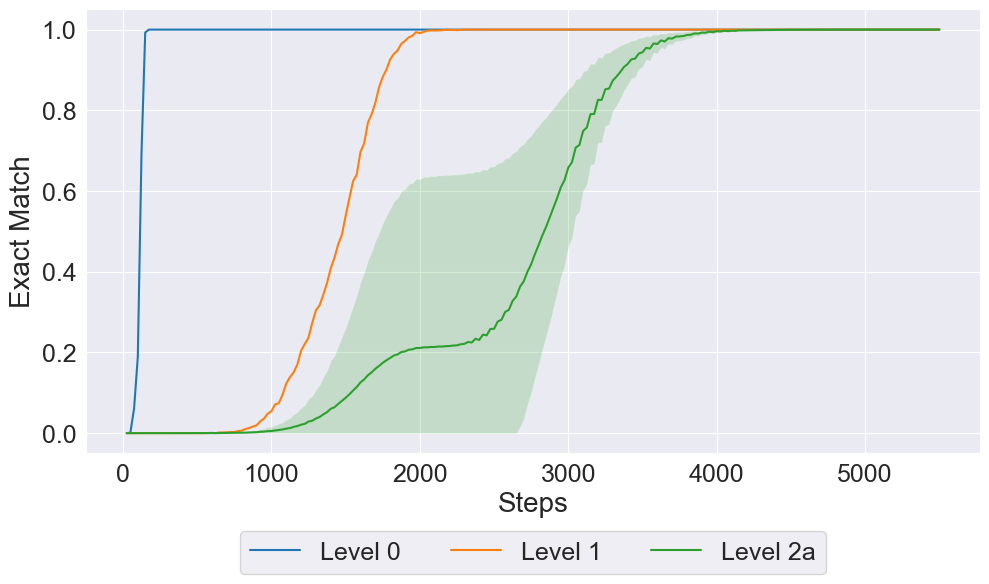

In [18]:
plot_aggregated_by_level("lookup")

In [7]:
data.columns

Index(['train/exact_match_repeated', 'train/global_step', '_run_id',
       '_run_name', 'cfg.dataset._target_', 'cfg.dataset.npz_path',
       'cfg.model.n_embd', 'cfg.model.n_head', 'cfg.model.n_layer',
       'cfg.model.freeze_embeddings', 'cfg.training.bf16', 'cfg.training.seed',
       'cfg.training.optim', 'cfg.training.max_steps',
       'cfg.training.report_to', 'cfg.training.batch_size',
       'cfg.training.save_steps', 'cfg.training.warmup_steps',
       'cfg.training.weight_decay', 'cfg.training.learning_rate',
       'cfg.training.logging_steps', 'cfg.training.max_grad_norm',
       'cfg.training.loss_logging_mode', 'cfg.training.lr_scheduler_type',
       'cfg.training.dataloader_pin_memory',
       'cfg.training.ignore_pad_tokens_in_loss',
       'cfg.training.gradient_accumulation_steps', 'cfg.dataset_metadata.seed',
       'cfg.dataset_metadata.seq_len', 'cfg.dataset_metadata.lookback',
       'cfg.dataset_metadata.strategy', 'cfg.dataset_metadata.pos',
       'cfg.dat

In [8]:
for col in data.columns:
    if col.startswith('cfg.dataset_metadata'):
        vals = data[col].unique()
        col_name = col.replace('cfg.dataset_metadata.', '')
        vals_name = ', '.join(str(v) for v in vals)
        print(f"{col_name}: {vals_name}")

seed: 0, 42, 15, 3, 4
seq_len: 100
lookback: None, 2
strategy: sin, lookback, random, formula, lookup, modulo, polynomial_prime
pos: None, 0
prefix_len: 50
vocab_size: 100
aggregation: lookup, formula, None
num_samples: 3000
target_level: 2a, 1, 0
random_prefix: True
